In [32]:
import math
from pydantic import BaseModel, Field
from typing import Annotated, Optional

from langgraph.graph import StateGraph

from IPython.display import Image, display

In [33]:
class AgentState(BaseModel):
    values: Annotated[list[int], Field(description="List of integers")]
    name: Annotated[str, Field(description="Name")]

    # By assigning = None, we're telling Pydantic that it's okay for 
    # result to be missing from input, and it will be populated later.
    # This default value is mandatory, because otherwise, an error will 
    # be raised while invoking the graph
    result: Annotated[Optional[str], Field(
            description="Result",
            default=None
        )]


def processValues(state: AgentState) -> AgentState:
    """
    Adds multiple different inputs
    """

    state.result = f"Hi there, {state.name}! Your sum = {sum(state.values)}"
    
    return state


def multiplyValues(state: AgentState) -> AgentState:
    """
    Multiplies multiple different inputs, and is supposed to execute 
    after the 'processValues' node
    """

    # here, we're updating the state instead of replacing it, so 
    # that we also have the previous context; thus, we can modify a 
    # state in as many nodes as we want
    state.result += f" Your product = {math.prod(state.values)}"
    
    return state

In [34]:
graph = StateGraph(AgentState)
graph.add_node("processor", processValues)
graph.add_node("multiplier", multiplyValues)

graph.set_entry_point("processor")

# the names of the connecting nodes should be provided
graph.add_edge("processor", "multiplier")

graph.set_finish_point("multiplier")

app = graph.compile()

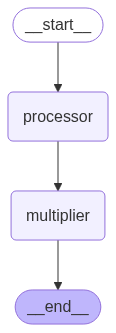

In [35]:
display(Image(app.get_graph().draw_mermaid_png()))

In [36]:
answers = app.invoke({
    "values": [1, 2, 3, 4],
    "name": "Steve"
})

In [37]:
answers

{'values': [1, 2, 3, 4],
 'name': 'Steve',
 'result': 'Hi there, Steve! Your sum = 10 Your product = 24'}

In [38]:
answers["result"]

'Hi there, Steve! Your sum = 10 Your product = 24'